# RQ3 - VAR mo rong + Impulse Response

Bien: lam phat (CHINH: CPI thang quy nam `cpi_mom_ann`; DOI CHIEU: so voi cung ky `cpi_yoy`), Fed Funds, Level, Slope, Curvature. Cholesky: lam phat → fed_funds → level → slope → curvature. Quet do tre p = 1..12, chon AIC nho nhat trong cac p co Portmanteau > 0,05 (neu khong co p nao dat thi lay AIC nho nhat va ghi ro).

In [1]:
import sys
sys.path.append('..')
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src import config, data_fetch, utils, interactive as ia
pd.options.display.float_format = '{:.4f}'.format
from src import var_analysis as va

## 1. Du lieu

In [2]:
factors_monthly = utils.ensure_monthly_freq(pd.read_csv('../data/ns_factors_monthly.csv', index_col=0))
_, macro, _ = data_fetch.fetch_fred_data(use_cache=True)
mm = utils.resample_to_monthly(macro)
mm['cpi_mom_ann'] = data_fetch.compute_cpi_mom_annualized(mm, winsor=config.VAR_INFLATION_WINSOR)  # chinh (cat 2% hai duoi)
mm['cpi_mom_ann_raw'] = data_fetch.compute_cpi_mom_annualized(mm)  # khong cat, de doi chieu
mm['cpi_yoy'] = data_fetch.compute_cpi_yoy(mm)
in_main = utils.ensure_monthly_freq(mm[['cpi_mom_ann', 'fed_funds']])
in_alt = utils.ensure_monthly_freq(mm[['cpi_yoy', 'fed_funds']])
mm[['cpi_mom_ann', 'cpi_yoy', 'fed_funds']].describe()

,cpi_mom_ann,cpi_yoy,fed_funds
count,331.0000,320.0000,332.0000
mean,2.6860,2.6011,2.1541
std,3.1397,1.7138,2.0596
min,-5.4732,-1.9588,0.0500
25%,0.7412,1.6658,0.1600
50%,2.6874,2.4057,1.5500
75%,4.3197,3.3385,4.2525
max,10.8229,8.9794,6.5400


## 2. Tinh dung (ADF co hang so + xu huong; KPSS) va bien doi
Bien I(1) theo ADF (p >= 0,05) duoc lay sai phan bac 1.

In [3]:
data_check = factors_monthly[['level','slope','curvature']].join(in_main, how='inner').dropna()
display(va.test_stationarity_all(data_check))
var_ready, transform_table = va.prepare_var_data(data_check)
transform_table

,series,adf_stat,adf_pvalue,kpss_stat,kpss_pvalue,kpss_note,likely_stationary
0,level,-1.2249,0.9053,1.4884,0.0100,p_actual<reported (stat outside table),False
1,slope,-4.0194,0.0083,0.7709,0.0100,p_actual<reported (stat outside table),False
2,curvature,-2.6708,0.2484,0.3417,0.1000,p_actual>reported (stat outside table),False
3,cpi_mom_ann,-4.1716,0.0049,0.3396,0.1000,p_actual>reported (stat outside table),True
4,fed_funds,-3.6681,0.0245,0.3789,0.0863,,True


,series,adf_p_level,transform,adf_p_after
0,level,0.9053,diff1,0.0000
1,slope,0.0083,level,0.0083
2,curvature,0.2484,diff1,0.0002
3,cpi_mom_ann,0.0049,level,0.0049
4,fed_funds,0.0245,level,0.0245


## 3. Fit VAR chinh + chon do tre

In [4]:
var_results, var_data = va.fit_var_model(factors_monthly, in_main, macro_cols=('cpi_mom_ann', 'fed_funds'))
print('p =', var_results.k_ar, '| luat:', var_results.lag_rule, '| Portmanteau OK:', var_results.whiteness_ok)
var_results.lag_table.round(4)

p = 4 | luat: AIC min trong cac p co Portmanteau>0.05 | Portmanteau OK: True


,p,AIC,BIC,HQIC,portmanteau_p,stable,max_abs_inv_root
0,1,-8.3847,-8.0298,-8.2430,0.0000,True,0.9793
1,2,-9.5683,-8.9161,-9.3077,0.0029,True,0.9755
2,3,-9.5363,-8.5855,-9.1565,0.0011,True,0.9703
3,4,-9.6782,-8.4274,-9.1785,0.0686,True,0.9650
4,5,-9.6483,-8.0960,-9.0281,0.0247,True,0.9525
5,6,-9.6286,-7.7735,-8.8873,0.0176,True,0.9642
6,7,-9.6013,-7.4418,-8.7382,0.0200,True,0.9651
7,8,-9.5505,-7.0853,-8.5651,0.0027,True,0.9678
8,9,-9.5019,-6.7296,-8.3936,0.0001,True,0.9639
9,10,-9.4547,-6.3738,-8.2229,0.0000,True,0.9564


**Chan doan phan du.** Portmanteau da bien la kiem dinh nghiem ngat; bang Ljung-Box tung phuong trinh cho thay phuong trinh nao con tu tuong quan.

In [5]:
display(va.residual_ljungbox(var_results, 12))
stab = va.check_var_stability(var_results)
print('on dinh:', stab['is_stable'], '| max nghich dao nghiem:', round(float(1/np.abs(stab['roots']).min()), 4))

,equation,lags,lb_stat,lb_pvalue
0,cpi_mom_ann,12,12.3221,0.4202
1,fed_funds,12,17.0182,0.1489
2,level,12,3.2711,0.9933
3,slope,12,9.8468,0.6294
4,curvature,12,8.2112,0.7684


on dinh: True | max nghich dao nghiem: 0.965


## 4. Granger

In [6]:
va.run_granger_causality_matrix(var_results, list(var_data.columns))

,caused,causing,test_stat,p_value,conclusion
0,cpi_mom_ann,fed_funds,1.8417,0.1184,fail to reject
1,cpi_mom_ann,level,1.0448,0.3827,fail to reject
2,cpi_mom_ann,slope,0.9718,0.4218,fail to reject
3,cpi_mom_ann,curvature,2.9650,0.0187,reject
4,fed_funds,cpi_mom_ann,2.3286,0.0542,fail to reject
5,fed_funds,level,36.9719,0.0000,reject
6,fed_funds,slope,43.6026,0.0000,reject
7,fed_funds,curvature,14.1750,0.0000,reject
8,level,cpi_mom_ann,0.1606,0.9582,fail to reject
9,level,fed_funds,1.0408,0.3848,fail to reject


## 5. IRF (Cholesky, cong don voi bien sai phan, KTC 95% bootstrap 300 lan)

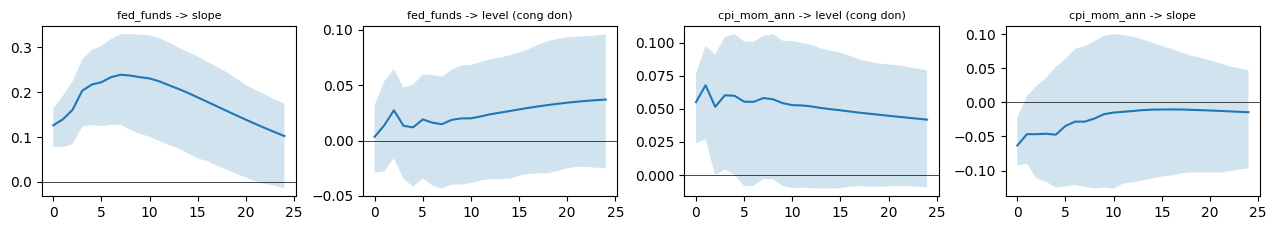

In [7]:
irf = va.irf_with_bands(var_results, var_results.transform_table, periods=24, n_boot=300)
irf_df = va.irf_to_frame(irf)
va.plot_irf_pairs(irf, pairs=[('fed_funds','slope'),('fed_funds','level'),('cpi_mom_ann','level'),('cpi_mom_ann','slope')])
plt.show()

### Tuong tac: luoi IRF va be mat 3D

In [8]:
ia.fig_irf_grid(irf_df).show()

In [9]:
ia.fig_irf_surface(irf_df, 'fed_funds').show()

In [10]:
ia.fig_irf_surface(irf_df, 'cpi_mom_ann').show()

## 6. Doi chieu: lam phat so voi cung ky (YoY)

In [11]:
res_yoy, data_yoy = va.fit_var_model(factors_monthly, in_alt, macro_cols=('cpi_yoy', 'fed_funds'))
print('YoY: p =', res_yoy.k_ar, '| luat:', res_yoy.lag_rule)
res_yoy.lag_table.round(4)

YoY: p = 12 | luat: AIC min (KHONG p nao dat Portmanteau>0.05)


,p,AIC,BIC,HQIC,portmanteau_p,stable,max_abs_inv_root
0,1,-12.2179,-11.8630,-12.0762,0.0000,True,0.9783
1,2,-13.4573,-12.8052,-13.1968,0.0000,True,0.9758
2,3,-13.4422,-12.4914,-13.0624,0.0000,True,0.9701
3,4,-13.5049,-12.2541,-13.0052,0.0000,True,0.9607
4,5,-13.4772,-11.9249,-12.8569,0.0000,True,0.9589
5,6,-13.4636,-11.6085,-12.7223,0.0000,True,0.9679
6,7,-13.4412,-11.2818,-12.5782,0.0000,True,0.9700
7,8,-13.4145,-10.9493,-12.4291,0.0000,True,0.9745
8,9,-13.3482,-10.5759,-12.2399,0.0000,True,0.9649
9,10,-13.3222,-10.2413,-12.0904,0.0000,True,0.9745


## 7. Do nhay (ket qua da luu boi pipeline): lag, thu tu Cholesky, YoY

In [12]:
rob = pd.read_csv('../outputs/rq3_irf_robustness.csv')
x = rob[(rob.impulse=='fed_funds') & (rob.response=='slope')]
x.pivot(index='spec', columns='h', values='irf').join(x.groupby('spec')[['lag','portmanteau_p']].first())

,1,6,12,24,lag,portmanteau_p
spec,,,,,,
Cholesky dao nguoc,-0.0032,0.0173,0.0110,-0.0109,4,0.0686
Cholesky: fed_funds dau,0.1293,0.2251,0.2102,0.0982,4,0.0686
Cholesky: nhan to truoc vi mo,-0.0067,0.0146,0.0055,-0.0150,4,0.0686
Lam phat so voi cung ky (YoY),0.1007,0.0913,0.0829,0.0491,12,0.0000
M/M quy nam KHONG winsorize,0.1454,0.2308,0.2202,0.1068,4,0.0160
Sai phan them fed_funds va slope (I(1)),0.1256,0.2285,0.2902,0.3208,4,0.1097
co so (AIC + Portmanteau),0.1398,0.2338,0.2158,0.1024,4,0.0686
lag=12,0.0973,0.0789,0.0859,0.0603,12,0.0000
lag=2 (BIC khong rang buoc),0.1774,0.2357,0.1947,0.1109,2,0.0029


## 8. Xuat

In [13]:
var_data.to_csv('../data/var_input_data.csv')
print('Da ghi var_input_data.csv', var_data.shape)

Da ghi var_input_data.csv (319, 5)
